<a href="https://colab.research.google.com/github/tsursnake/52025-COURSE-YOHAN-GROSS/blob/main/assignment2/PS1_Part3_Autograd_2026_ID_329758296.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PyTorch - Autograd (is what we need.)

Advanced Learning 2026





For SUBMISSION:  
  
Please upload the complete and executed `ipynb` to your git repository. Verify that all of your output can be viewed directly from github, and provide a link to that git file below.

~~~
STUDENT ID: 329758296
~~~

~~~
STUDENT GIT LINK: https://github.com/tsursnake/52025-COURSE-YOHAN-GROSS/blob/main/assignment_2/PS1_Part3_Autograd_2026_ID_329758296.ipynb
~~~

In Addition, don't forget to add your ID to the files:  
`PS1_Part3_Autograd_2026_ID_[000000000].html`  



This part of the problem-set is divided into 2 sections: (a) a short introduction to PyTorch autograd, and (b) some practice questions.      
The practice questions cover calculating the gradients and updating the weights of a statistical model (linear regression), with and without PyTorch autograd.

##  A Short Intro to PyTorch Autograd

In PyTorch, autograd, short for automatic differentiation, is a core functionality that empowers you to efficiently calculate gradients during deep learning model training. It acts as a computational engine that automatically tracks the operations performed on your tensors and calculates the gradients of any loss function with respect to the model's learnable parameters.

**Why is Autograd Important?**

* Gradient Calculation: Deep learning relies heavily on gradient-based optimization algorithms like stochastic gradient descent (SGD). These algorithms adjust the weights and biases (learnable parameters) of your model based on the gradients of the loss function. Autograd automates this process, saving you from manually calculating complex derivatives.
* Efficient Backpropagation: Backpropagation is the algorithm at the heart of training deep neural networks. It propagates the error (loss) backward through the network, allowing the model to adjust its parameters in the direction that minimizes the loss. Autograd streamlines this process, making training more efficient.

**How Does Autograd Work?**

* Tracking Operations: When you enable autograd mode (with `torch.enable_grad()`), PyTorch creates a computational graph in the background. This graph tracks all the operations performed on your tensors

* Backward Pass: Once you calculate a loss function (which typically depends on the output of your model), you can call the `backward()` method on the loss tensor. This triggers the backward pass through the computational graph.

* Gradient Calculation: As the backward pass traverses the graph, autograd computes the gradients of the loss function with respect to each learnable parameter in the network. These gradients indicate how much a specific parameter contributed to the overall loss.

* Parameter Update: By utilizing these gradients, optimization algorithms like SGD update the model's learnable parameters in a direction that minimizes the loss function. This iterative process continues until the model converges (achieves a desired level of performance).

**Key Points about Autograd:**

* Automatic
* Only for Learnable Parameters: Autograd tracks gradients only for tensors that have `requires_grad=True`.
* Dynamic vs. Static Graphs (Optional): PyTorch offers both dynamic computational graphs (eager execution) and static graphs (graph mode) for model development.



In [16]:
import time
import numpy as np
import pandas as pd
import torch
import math
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import DataLoader

In [17]:
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_default_device(device)
print(f"Using {device}!")

Using cuda!


##  0. Loading data and defining our model and loss

Load the California Housing Market dataset into a panda's DataFrame.  
In addition, scale the data (why?).

In [18]:
# Import the dataset.
cali_train_path = "https://download.mlcc.google.com/mledu-datasets/california_housing_train.csv"
train_df = pd.read_csv(filepath_or_buffer=cali_train_path).drop(['longitude','latitude'],axis=1)
train_df_norm=(train_df-train_df.mean(axis=0))/train_df.std(axis=0) # column-wise operators
# Scale the labels:
print(f"Dataset dimension: {train_df_norm.shape}")
train_df_norm.head()

Dataset dimension: (17000, 7)


,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-1.079639,1.361655,1.764152,-0.361173,-0.075996,-1.252506,-1.210522
1,-0.761850,2.296540,3.230346,-0.261858,-0.099401,-1.081451,-1.096713
2,-0.920744,-0.882436,-0.866931,-0.955326,-0.999223,-1.170071,-1.048430
3,-1.159087,-0.524171,-0.480216,-0.796769,-0.715753,-0.362590,-1.154480
4,-0.682402,-0.545731,-0.506313,-0.701809,-0.622130,-1.026424,-1.222593


We define a linear model to fit the scaled median house value to our data:  

**Our model :**.    

 $$\text{median_house_value}_i=y_i = \beta_0+	\beta_1\text{housing_median_age}_i+ 	\beta_2\text{total_rooms}_i+ 	\beta_3\text{total_bedrooms}_i+ 	\beta_4\text{population}_i+ 	\beta_5\text{households}_i+ 	\beta_6\text{median_income}_i 	$$

**Our loss :**  
$$
\hat{L}_i(y_i,\hat{y}_i) = MSE(\text{y}_i,\hat{\text{y}}_i)
$$


## 1.  Manually Calculating the Gradients and Updating the Weights



Here we take a step back, and implement forward and backward propogation manually (so we can fully appreciate the autograd later...).

First, create numpy arrays for our data (X) and target (Y):

In [19]:
X = train_df_norm.drop(['median_house_value'],axis=1).to_numpy()
X =  np.c_[  np.ones(X.shape[0]), X] # adding a column of "1"s for intercept
Y = train_df_norm['median_house_value']

print(f"X dimension: {X.shape}")
print(f"Y dimension: {Y.shape}")

X dimension: (17000, 7)
Y dimension: (17000,)


### 1.1 Calculating the weights analytically (15pts)
Apply linear algebra operations to `X` and `Y` to analytically solve the linear regression problem (solve for `W`).   
Please use only numpy. Round the weights to 3 decimal places.  

In [20]:
#### SOLUTION REQUIRED ####
t1 = time.time()

weights_rounded = np.linalg.solve(X.T @ X, X.T @ Y.to_numpy()).round(3)
print(f"Total process time: {round(time.time() - t1,3)}")
print(f"The estimated weights using the analytic solution:\n {weights_rounded.round(3)}")

Total process time: 0.001
The estimated weights using the analytic solution:
 [ 0.     0.204 -0.375  0.362 -0.347  0.422  0.79 ]


Visualizing the errors:

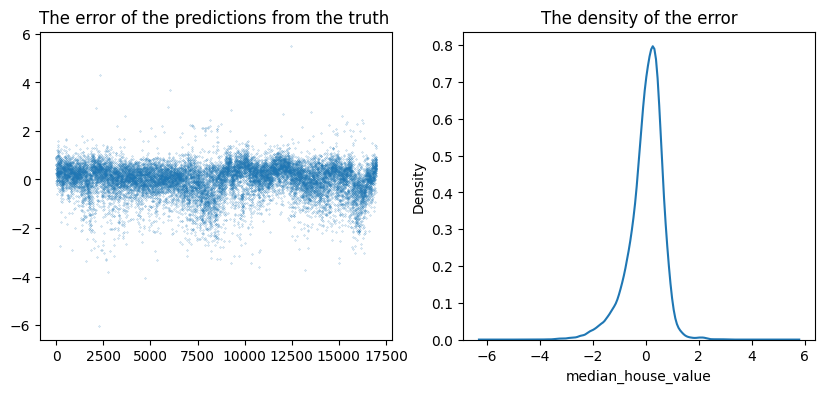

In [21]:
# Plot the errors and density (sanity check):
fig, (ax1,ax2) = plt.subplots(nrows=1, ncols=2,figsize=(10,4))
error = (np.matmul( X, weights_rounded)-Y)
ax1.scatter(range(Y.shape[0]), error ,s=0.05,alpha=0.7)
ax1.set_title("The error of the predictions from the truth ")
sns.kdeplot(error,ax=ax2)
ax2.set_title("The density of the error")
fig.show()


### 1.2 Calculating the weights using numpy and gradient descent (30pts)

Now you are ready to implement an algorithm that iteratively calculates the weights using numpy and gradient descent.

Please fill in your code in the `### YOUR CODE HERE` sections in the code block below.   
Please don't change the other parts of the code (unless specified).  

An epoch in machine learning means one complete pass of the training dataset through the algorithm.   

While developing your code, you may reduce the number of epochs.   
However, for final output please use the pre-defined epochs number.      





In [22]:
#### SOLUTION REQUIRED ####

t2 = time.time()

# Randomly initialize weights using numpy
b0 = np.random.randn()
b1 = np.random.randn()
b2 = np.random.randn()
b3 = np.random.randn()
b4 = np.random.randn()
b5 = np.random.randn()
b6 = np.random.randn()

# Set learning rate (this can be a little fiddly, requires some tunning)
# Tip: start with a very small steps...

learning_rate = 0.1

# Set number of epochs:
epochs = int(5e3)

# Loop through epochs, and apply gradient descent to update the weights:
for t in range(epochs):
    # Forward pass: compute predicted y
    # y_pred = b0x0 + b1x1 + b2x2 + b3x3 + b4x4 + b5x5 + b6x6
    Y_pred = b0 * X[:, 0] + b1 * X[:, 1] + b2 * X[:, 2] + b3 * X[:, 3] + b4 * X[:, 4] + b5 * X[:, 5] + b6 * X[:, 6]

    # Compute and print loss
    loss = ((Y_pred - Y.values) ** 2).mean()
    if t % 1000 == 0:
        print(f"Epoch:{t}, loss:{loss}")

    # Backprop to compute gradients of betas with respect to loss
    grad_y_pred = 2 * (Y_pred - Y.values) / len(Y)
    grad_b0 = (grad_y_pred * X[:, 0]).sum()
    grad_b1 = (grad_y_pred * X[:, 1]).sum()
    grad_b2 = (grad_y_pred * X[:, 2]).sum()
    grad_b3 = (grad_y_pred * X[:, 3]).sum()
    grad_b4 = (grad_y_pred * X[:, 4]).sum()
    grad_b5 = (grad_y_pred * X[:, 5]).sum()
    grad_b6 = (grad_y_pred * X[:, 6]).sum()

    # Update weights
    b0 -= learning_rate * grad_b0
    b1 -= learning_rate * grad_b1
    b2 -= learning_rate * grad_b2
    b3 -= learning_rate * grad_b3
    b4 -= learning_rate * grad_b4
    b5 -= learning_rate * grad_b5
    b6 -= learning_rate * grad_b6

print(f"Result: y_hat = {b0} x0 + {b1} x1 + {b2} x2 + {b3} x3\n + {b4} x4 + {b5} x5 + {b6} x6 \n")
print(f"Total process time: {round(time.time() - t2,3)}")

weights_gd_rounded = np.array([b0,b1,b2,b3,b4,b5,b6])
print(f"The estimated weights using the gradient descent solution:\n {weights_gd_rounded.round(3)}")

Epoch:0, loss:8.702059409329705
Epoch:1000, loss:0.4287426390277883
Epoch:2000, loss:0.42862684457127087
Epoch:3000, loss:0.42862651132606305
Epoch:4000, loss:0.42862651036701566
Result: y_hat = 3.518431165712675e-16 x0 + 0.20402526188822798 x1 + -0.37507696515237354 x2 + 0.3616849011655339 x3
 + -0.3465639844603166 x4 + 0.4217904588979901 x5 + 0.7902429707900054 x6 

Total process time: 1.653
The estimated weights using the gradient descent solution:
 [ 0.     0.204 -0.375  0.362 -0.347  0.422  0.79 ]


### 1.3 Calculating the weights using PyTorch Tensors and gradient descent (25pts)

Here you are asked to implement the same manual gradient algorithm as above.  
However, this time please use PyTorch tensors and operators (instead of numpy).  

In [23]:
#### SOLUTION REQUIRED ####

# Creating data and target tensors:
tX = torch.tensor(X, dtype=torch.float32)
tY = torch.tensor(Y.to_numpy(), dtype=torch.float32)

t3 = time.time()

# Randomly initialize weights using PyTorch
tb0 = torch.randn(())
tb1 = torch.randn(())
tb2 = torch.randn(())
tb3 = torch.randn(())
tb4 = torch.randn(())
tb5 = torch.randn(())
tb6 = torch.randn(())

# Set learning rate
learning_rate = 0.1

# Set number of epochs:
epochs = int(5e3)

# Loop through epochs, and apply gradient descent to update the weights:
for t in range(epochs):
    # Forward pass: compute predicted y
    # y_pred = b0x0 + b1x1 + b2x2 + b3x3 + b4x4 + b5x5 + b6x6
    tY_pred = tb0 * tX[:, 0] + tb1 * tX[:, 1] + tb2 * tX[:, 2] + tb3 * tX[:, 3] + tb4 * tX[:, 4] + tb5 * tX[:, 5] + tb6 * tX[:, 6]

    # Compute and print loss
    loss = ((tY_pred - tY) ** 2).mean()
    if t % 1000 == 0:
        print(f"epoch:{t}, loss:{loss}")

    # Backprop to compute gradients of betas with respect to loss
    grad_y_pred = 2 * (tY_pred - tY) / len(tY)
    # print(grad_y_pred.sum())
    grad_b0 = (grad_y_pred * tX[:, 0]).sum()
    grad_b1 = (grad_y_pred * tX[:, 1]).sum()
    grad_b2 = (grad_y_pred * tX[:, 2]).sum()
    grad_b3 = (grad_y_pred * tX[:, 3]).sum()
    grad_b4 = (grad_y_pred * tX[:, 4]).sum()
    grad_b5 = (grad_y_pred * tX[:, 5]).sum()
    grad_b6 = (grad_y_pred * tX[:, 6]).sum()

    # Update weights
    tb0 -= learning_rate * grad_b0
    tb1 -= learning_rate * grad_b1
    tb2 -= learning_rate * grad_b2
    tb3 -= learning_rate * grad_b3
    tb4 -= learning_rate * grad_b4
    tb5 -= learning_rate * grad_b5
    tb6 -= learning_rate * grad_b6

print(f"Result: y_hat = {tb0} x0 + {tb1} x1 + {tb2} x2 + {tb3} x3\n + {tb4} x4 + {tb5} x5 + {tb6} x6 \n")
print(f"Total process time: {round(time.time() - t3,3)}")

weights_gd_tensors_rounded = np.array([tb0.item(),tb1.item(),tb2.item(),tb3.item(),
                                       tb4.item(),tb5.item(),tb6.item()])
print(f"The estimated weights using the gradient descent on tensors:\n {weights_gd_tensors_rounded.round(3)}")

epoch:0, loss:3.42545485496521
epoch:1000, loss:0.42863595485687256
epoch:2000, loss:0.42862656712532043
epoch:3000, loss:0.42862650752067566
epoch:4000, loss:0.42862653732299805
Result: y_hat = 7.309022276302812e-09 x0 + 0.20402535796165466 x1 + -0.37507885694503784 x2 + 0.361690878868103 x3
 + -0.34656262397766113 x4 + 0.42178505659103394 x5 + 0.7902436256408691 x6 

Total process time: 3.948
The estimated weights using the gradient descent on tensors:
 [ 0.     0.204 -0.375  0.362 -0.347  0.422  0.79 ]


### 1.4 Calculating the weights using PyTorch Autograd! (15pts)

Lastly, you can finally make a full transition to PyTorch autograd framework.   
Please replace your manual gradient calculations with PyTorch's automatic gradient tracking.   
In addition, instead of declaring the parameters separately, we will use one tensor to represent all of the model's parameters.  

In [24]:
#### SOLUTION REQUIRED ####

t4 = time.time()

# Randomly initialize weights using PyTorch.
# Use a single 1-D tensor of shape (7,) for all the weights. Make sure requires_grad=True.
tb = torch.randn(7, requires_grad=True)


# Set learning rate
learning_rate = 0.1
# Set number of epochs:
epochs = int(5e3)

# Loop through epochs, and apply gradient descent to update the weights:
for t in range(epochs):

    # Forward pass: compute predicted y
    tY_pred = tX @ tb

    # Compute and print loss
    loss = ((tY_pred - tY) ** 2).mean()
    if t % 1000 == 0:
        print(f"epoch:{t}, loss:{loss.item()}")

    # Backprop to compute gradients of betas with respect to loss
    loss.backward()

    with torch.no_grad():
        # Update weights
        tb -= learning_rate * tb.grad
        tb.grad = None # manually clear gradient after update


print(f"Result: betas = {tb} \n")
print(f"Total process time: {round(time.time() - t4,3)}")

weights_autograd_rounded = tb.cpu().detach().numpy()
print(f"The estimated weights using the pytorch autograd:\n {weights_autograd_rounded.round(3)}")

epoch:0, loss:6.474329471588135
epoch:1000, loss:0.42862892150878906
epoch:2000, loss:0.42862653732299805
epoch:3000, loss:0.42862650752067566
epoch:4000, loss:0.42862653732299805
Result: betas = tensor([ 1.8826e-09,  2.0403e-01, -3.7508e-01,  3.6168e-01, -3.4657e-01,
         4.2179e-01,  7.9024e-01], device='cuda:0', requires_grad=True) 

Total process time: 3.174
The estimated weights using the pytorch autograd:
 [ 0.     0.204 -0.375  0.362 -0.347  0.422  0.79 ]


### 1.5 Conclusion (15pts)

1. Which method is the most accurate in finding the "true" weights? Why? Is it always applicabale? Hint - you should think about it from a statistical theory point of view.
2. Why did we scale the data ?  (answer with respect to the model/algorithm)
3. Do you think our model specification produced good results?  Why or why not? Justify your answer.
4. What can you say about the total process times between methods?
5. Can you suggest some improvements to the model definition?
6. Can you suggest some improvements to the solution algorithm?

YOUR ANSWERS HERE

1. The analytic solution is the most accurate. It is the exact minimizer of the squared error, and under the usual linear model assumptions it is the OLS estimator (best linear unbiased by Gauss-Markov, and the MLE if the errors are normal). The three gradient descent versions end at the same weights (same values to 3 decimals), but only because the learning rate and the number of epochs were good enough, they only approximate the minimum. It is not always applicable: it needs X'X to be invertible (no exact collinearity, more rows than features), it costs about p^3 operations, and most models, like neural networks, have no closed form at all.   
2. Gradient descent updates every weight with the same learning rate. With raw features on very different scales (total_rooms in the thousands, median_income around 1 to 10) the loss surface is very stretched: a learning rate small enough for the big features barely moves the small ones, and a larger one diverges. After standardizing, all columns have the same scale, the loss is better conditioned and one learning rate works for all weights (0.1 here). It also puts the intercept near 0 and makes a random init around 0 reasonable.   
3. Not really. The final loss is about 0.43 and the scaled target has variance 1, so the model explains only about 57% of the variance. Most of the signal comes from median_income. total_rooms, total_bedrooms, population and households are highly correlated with each other (0.86 to 0.98), so their coefficients have opposite signs that partly cancel and are hard to interpret. The target is capped at 500001 (about 5% of the rows), which a line cannot fit, and we dropped longitude and latitude even though location matters a lot for house prices. It is a fine baseline, not a good model.   
4. The analytic solution is by far the fastest, it solves one 7x7 system, while the three other methods run 5000 iterations over all 17000 rows. Between them the differences are mostly overhead and not different math. PyTorch is not faster than numpy here: the data is tiny, so per-operation overhead dominates (and on a GPU it can be even slower because of kernel launches). Autograd is faster than the manual tensor version because it uses one weight vector and one matrix product instead of 7 separate weights and 7 separate gradient sums, and it saves us from deriving the gradients.   
5. Put longitude and latitude back (maybe with a nonlinear function of location), take the log of the skewed count features (rooms, bedrooms, population, households) or use ratios like rooms per household, add nonlinear terms or interactions (especially for median_income), deal with the capped values (drop them or use a model for censored data), and use ridge regularization to stabilize the correlated features.
6. Use mini-batch or stochastic gradient descent, momentum or Adam with a learning rate schedule so the learning rate needs less tuning, and stop when the loss stops improving (here it is flat after about 3000 epochs) instead of a fixed 5000. For the closed form, use np.linalg.lstsq or QR instead of solving with X'X, it is more stable numerically.
